In [1]:
from typing import List, TypedDict
import time

from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

C:\Users\user\AppData\Local\Temp\ipykernel_48288\843203835.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


False

In [4]:
docs = PyPDFLoader("../documents/MilanRaiMERN.pdf").load()

In [6]:
len(docs)

1

In [9]:
#Splitting 
spliting = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = spliting.split_documents(docs)

In [10]:
len(chunks)

3

In [11]:
#Clean text to avoid UnicodeEncoderError
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [12]:
len(chunks)

3

In [13]:
embeddings = OllamaEmbeddings(model="bge-m3")


In [14]:
vector_store = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings, 
    persist_directory="../chromadb_basic_rag"
)

In [15]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={'k': 4})

In [16]:
llm = ChatOllama(model="llama3.2")

In [17]:
class State(TypedDict): 
    question: str
    docs: List[Document]
    answer: str

In [18]:
def retriever(state: State):
    q = state['question']
    return {"docs": retriever.invoke(q)}

In [21]:
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If the answer is not in the context, say you don't know."),
        ("human", "Question: {question}\n\nContext: {context}")
    ]
)


In [23]:
def generate(state: State): 
    context = "\n\n".join(d.page_content for d in state['docs'])
    out = (prompt | llm).invoke({"question": state['question'], "context": context})
    return {"answer": out.content}


In [27]:
# Node
graph = StateGraph(State)
graph.add_node("retriever", retriever)
graph.add_node("generate", generate)

# edges

graph.add_edge(START, "retriever")
graph.add_edge("retriever", "generate")
graph.add_edge("generate", END)

graph = graph.compile()


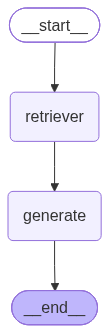

In [28]:
graph